# Experiment 10: Expectation-Maximization (EM) Algorithm
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a Python program to implement the **Expectation-Maximization (EM)** algorithm.

## Algorithm (Gaussian Mixture Model, K = 2, 1-D data)
* **Initialise** means, variances and mixing weights.
* **E-step:** compute the responsibility of each component for every point  
  `gamma_ik = pi_k N(x_i | mu_k, sigma_k^2) / sum_j pi_j N(x_i | mu_j, sigma_j^2)`
* **M-step:** re-estimate `pi_k`, `mu_k`, `sigma_k^2` using the responsibilities.
* Repeat until the log-likelihood stops improving.

Number of points: 500


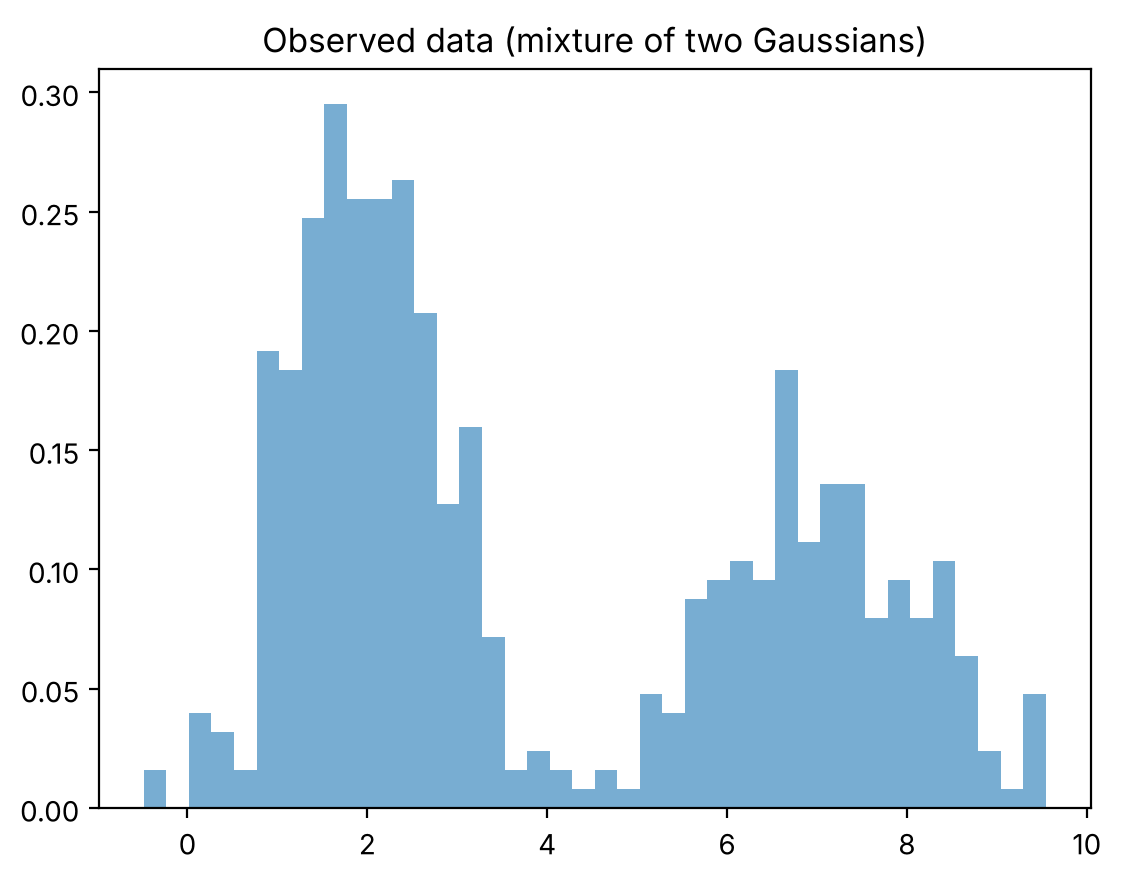

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.mixture import GaussianMixture

# Data drawn from two Gaussians (the "true" parameters are hidden from EM)
rng = np.random.default_rng(0)
data = np.concatenate([rng.normal(2.0, 0.8, 300), rng.normal(7.0, 1.2, 200)])
print('Number of points:', len(data))

plt.hist(data, bins=40, density=True, alpha=0.6)
plt.title('Observed data (mixture of two Gaussians)'); plt.show()

In [2]:
def em_gmm(x, k=2, max_iter=200, tol=1e-6):
    # initial guesses
    mu = np.array([x.min() + 1.0, x.max() - 1.0])
    var = np.array([1.0, 1.0])
    pi = np.array([0.5, 0.5])
    log_liks = []

    for it in range(1, max_iter + 1):
        # ---- E-step: responsibilities ----
        dens = np.array([pi[j] * norm.pdf(x, mu[j], np.sqrt(var[j])) for j in range(k)])   # k x n
        gamma = dens / dens.sum(axis=0)

        # ---- M-step: update parameters ----
        Nk = gamma.sum(axis=1)
        mu = (gamma * x).sum(axis=1) / Nk
        var = (gamma * (x - mu[:, None]) ** 2).sum(axis=1) / Nk
        pi = Nk / len(x)

        ll = np.sum(np.log(dens.sum(axis=0)))
        log_liks.append(ll)
        if it % 5 == 1:
            print(f'Iter {it:3d} | log-likelihood = {ll:10.4f} | mu = {np.round(mu, 3)} | pi = {np.round(pi, 3)}')
        if it > 1 and abs(log_liks[-1] - log_liks[-2]) < tol:
            print(f'Converged after {it} iterations.')
            break
    return mu, var, pi, log_liks

mu, var, pi, ll_hist = em_gmm(data)
print('\nEstimated means    :', np.round(mu, 3))
print('Estimated std-devs :', np.round(np.sqrt(var), 3))
print('Estimated weights  :', np.round(pi, 3))

Iter   1 | log-likelihood = -1564.3518 | mu = [1.986 7.063] | pi = [0.608 0.392]
Iter   6 | log-likelihood =  -996.3500 | mu = [1.972 7.033] | pi = [0.604 0.396]
Converged after 9 iterations.

Estimated means    : [1.972 7.033]
Estimated std-devs : [0.806 1.114]
Estimated weights  : [0.604 0.396]


sklearn means    : [1.973 7.036]
sklearn std-devs : [0.808 1.11 ]
sklearn weights  : [0.604 0.396]


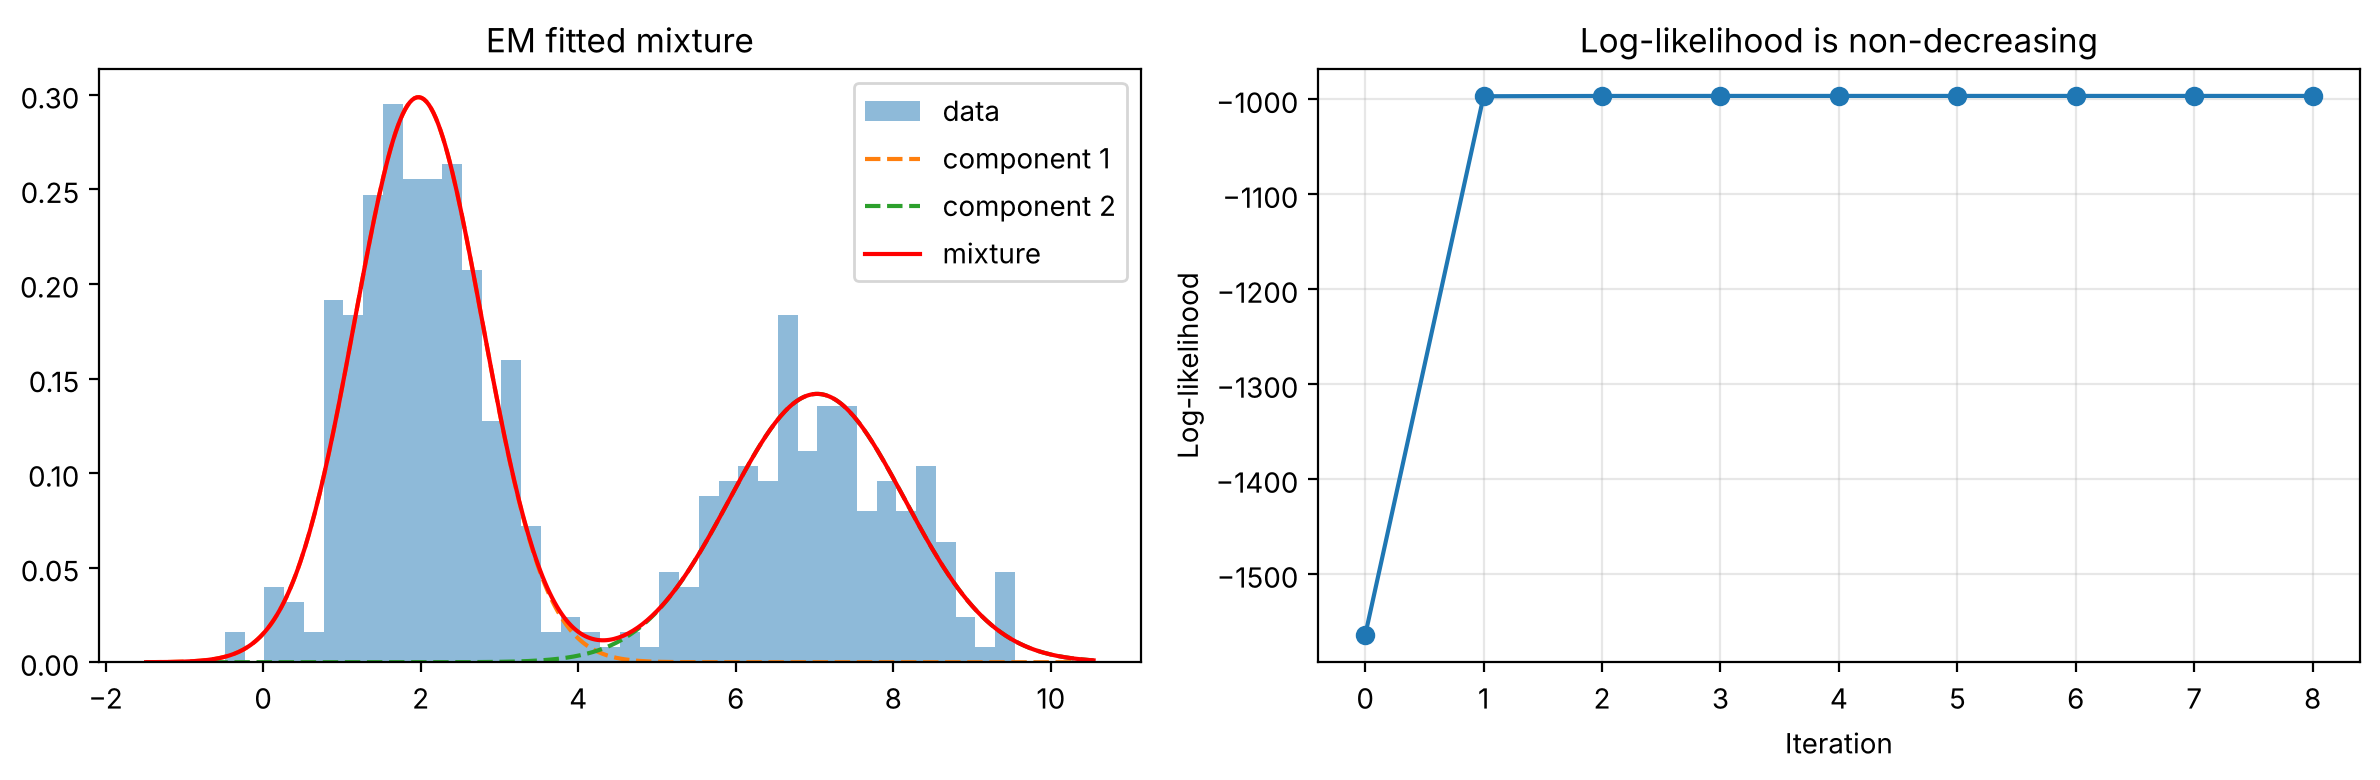

In [3]:
# Compare with scikit-learn's GaussianMixture
gm = GaussianMixture(n_components=2, random_state=0).fit(data.reshape(-1, 1))
order = np.argsort(gm.means_.ravel())
print('sklearn means    :', np.round(gm.means_.ravel()[order], 3))
print('sklearn std-devs :', np.round(np.sqrt(gm.covariances_.ravel()[order]), 3))
print('sklearn weights  :', np.round(gm.weights_[order], 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(data.min() - 1, data.max() + 1, 400)
ax[0].hist(data, bins=40, density=True, alpha=0.5, label='data')
total = np.zeros_like(xs)
for j in range(2):
    comp = pi[j] * norm.pdf(xs, mu[j], np.sqrt(var[j]))
    ax[0].plot(xs, comp, '--', label=f'component {j + 1}')
    total += comp
ax[0].plot(xs, total, 'r', label='mixture'); ax[0].legend(); ax[0].set_title('EM fitted mixture')
ax[1].plot(ll_hist, marker='o'); ax[1].set_xlabel('Iteration'); ax[1].set_ylabel('Log-likelihood')
ax[1].set_title('Log-likelihood is non-decreasing'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Result
EM recovers the hidden mixture parameters (means near 2 and 7, weights near 0.6 / 0.4). The log-likelihood increases monotonically until convergence, and the estimates agree with scikit-learn's `GaussianMixture`.